In [76]:
!pip install ucimlrepo
!pip install seaborn

'pip' is not recognized as an internal or external command,
operable program or batch file.
'pip' is not recognized as an internal or external command,
operable program or batch file.


Objetivo: Predecir el consumo de combustible ('mpg' => millas por galón) de un vehículo a partir de sus características técnicas, siguiendo un flujo de ML completo: carga, EDA, limpieza, modelo base, evaluación y registro en MLFlow.
Problema: Aprendizaje supervisado, regresión múltiple univariante, un único target continuo: mpg. 

Dataset: AUTO MPG, link: https://archive.ics.uci.edu/dataset/9/auto+mpg

# 0. Configuracion del entorno

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import mlflow
import mlflow.sklearn

from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

RANDOM_STATE = 42

c:\Users\FernandoSoft\.conda\envs\mlops\Lib\site-packages\requests\__init__.py:92: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(
C:\Users\FernandoSoft\AppData\Roaming\Python\Python311\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# 1. Carga y descripcion del dataset

In [78]:
# Importar los datos del dataset Auto MPG desde el repositorio de UCI
auto_mpg = fetch_ucirepo(id=9)
df = auto_mpg.data.original.copy()

# Estructura: 398 registros y 9 columnas (1 str, 4 int64 y 4 float64)
print("Registros y columnas:", df.shape)
df.info()

# cylinders y model_year figuran como Integer; su naturaleza discreta se verifica en el EDA
# car_name es ID: no se usa como feature por su alta cardinalidad; se conserva para detectar duplicados
display(auto_mpg.variables)
# horsepower tiene 6 valores faltantes
display(df.isna().sum())

Registros y columnas: (398, 9)
<class 'pandas.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   car_name      398 non-null    str    
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    int64  
 8   mpg           398 non-null    float64
dtypes: float64(4), int64(4), str(1)
memory usage: 34.4 KB


,name,role,type,demographic,description,units,missing_values
0,displacement,Feature,Continuous,None,None,None,no
1,mpg,Target,Continuous,None,None,None,no
2,cylinders,Feature,Integer,None,None,None,no
3,horsepower,Feature,Continuous,None,None,None,yes
4,weight,Feature,Continuous,None,None,None,no
5,acceleration,Feature,Continuous,None,None,None,no
6,model_year,Feature,Integer,None,None,None,no
7,origin,Feature,Integer,None,None,None,no
8,car_name,ID,Categorical,None,None,None,no


car_name        0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
mpg             0
dtype: int64

In [79]:
# Primeros registros
display(df.head())

# origin indica la región de fabricación. Se toma un vehículo de ejemplo por grupo para verificar los códigos:
# 1 = USA, 2 = Europa, 3 = Japón
# Es categórica nominal guardada como entero (tipo incorrecto).
df.groupby('origin', as_index=False).first()[['origin', 'car_name']]

,car_name,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,mpg
0,"chevrolet,chevelle,malibu",8,307.0,130.0,3504,12.0,70,1,18.0
1,"buick,skylark,320",8,350.0,165.0,3693,11.5,70,1,15.0
2,"plymouth,satellite",8,318.0,150.0,3436,11.0,70,1,18.0
3,"amc,rebel,sst",8,304.0,150.0,3433,12.0,70,1,16.0
4,"ford,torino",8,302.0,140.0,3449,10.5,70,1,17.0


,origin,car_name
0,1,"chevrolet,chevelle,malibu"
1,2,"volkswagen,1131,deluxe,sedan"
2,3,"toyota,corona,mark,ii"


# 2. Analisis exploratorio EDA

In [80]:

#Se crea una copia del dataset para el EDA para no alterar los datos que se limpiaran y usaran en el entrenamiento
df_eda = df.copy()

#Se crea una columna auxiliar para mostrar el origen de los vehiculos en el EDA, para que sea mas facil de interpretar
df_eda['origin_label'] = df_eda['origin'].map({1: 'USA', 2: 'Europa', 3: 'Japón'})

num_cols = ['mpg', 'displacement', 'horsepower', 'weight', 'acceleration']

#Origin: USA 249 registros, Europa 70 registros, Japón 79 registros, claramente una variable desbalanceada.
#Cylinders: Dominan los 4, 6 y 8, el modelo tendra muy poca informacion para aprender de los 3 y 5 cilindros.
for col in ['origin_label', 'cylinders', 'model_year']:
    print(df_eda[col].value_counts().sort_index(), "\n")


origin_label
Europa     70
Japón      79
USA       249
Name: count, dtype: int64 

cylinders
3      4
4    204
5      3
6     84
8    103
Name: count, dtype: int64 

model_year
70    29
71    28
72    28
73    40
74    27
75    30
76    34
77    28
78    36
79    29
80    29
81    29
82    31
Name: count, dtype: int64 



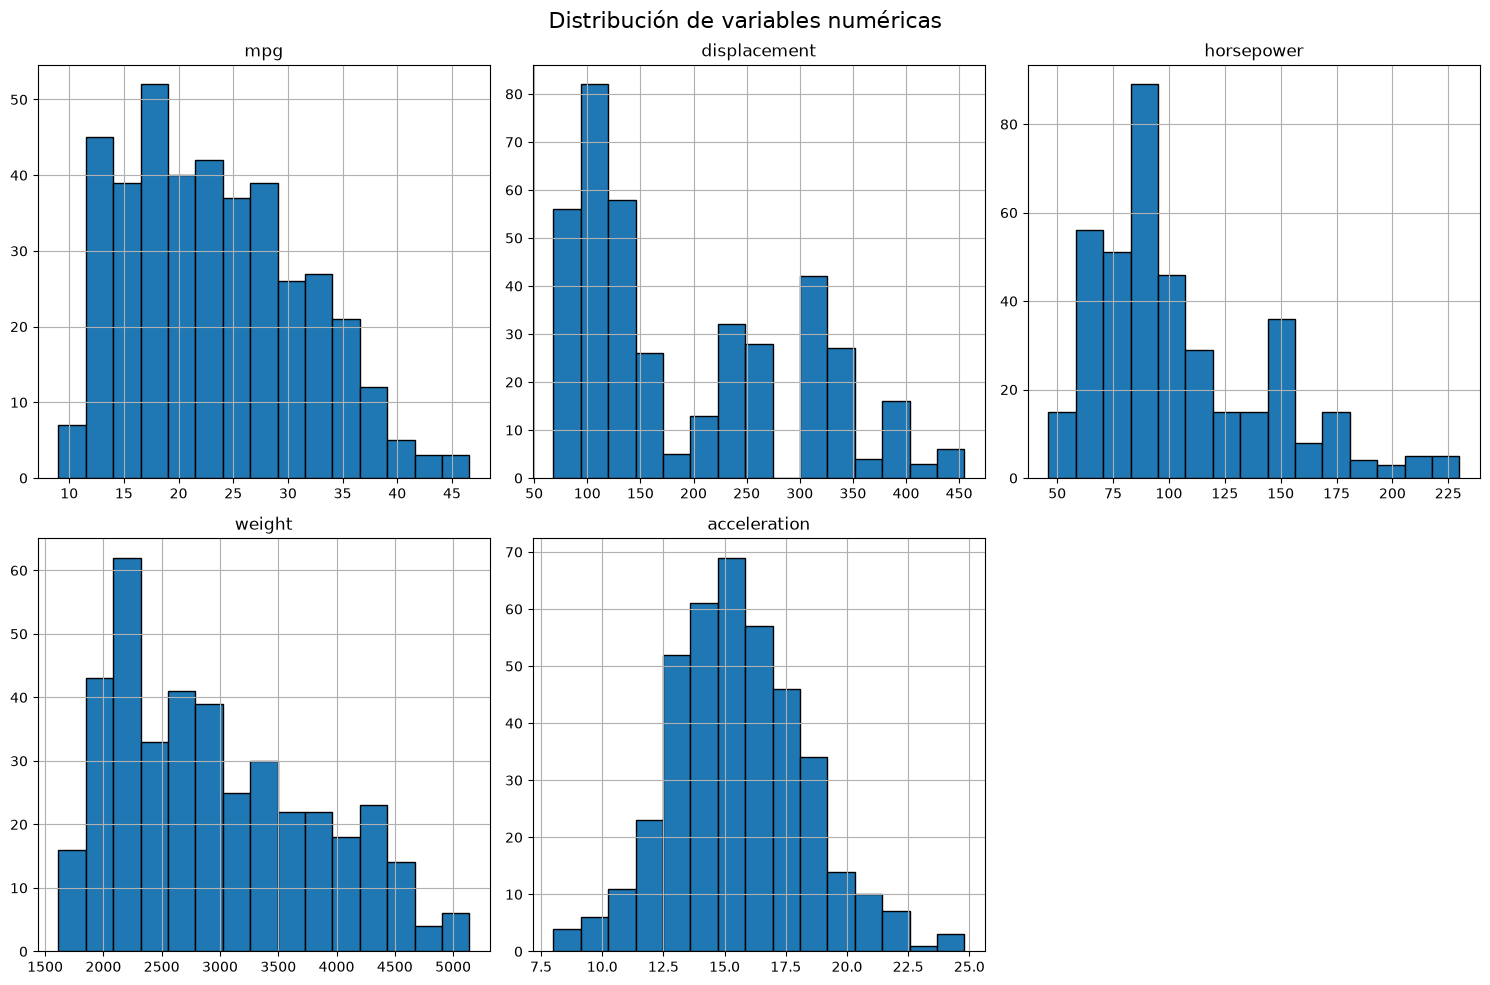

In [81]:
#MPG tiene sesgo a la derecha, la mayoria esta entre 13 y 30 mpg y pocos eficientes arriba de 30 mpg.
#Displacemente: Distribucion multimodal, con grupos alrededor de 100m 250 y 320, corresponden a los 4, 6 y 8 cilindros respectivamente.
#Horsepower: Sesgo a la derecha, la mayoria de los vehiculos tienen entre 60 y 110 hp, un pico esta en los 150 supongo que son los autos de 8 cilindros.
#Weight: Sesgo a la derecha, la mayoria de los vehicuylos estan entre 2000 y 3000 lbs.
#Aceleracion: La unica simetrica, el 0-60 centrado en los 15 segundos.
df_eda[num_cols].hist(bins=15, figsize=(15, 10), layout=(2, 3), edgecolor='black')
plt.suptitle('Distribución de variables numéricas', fontsize=16)
plt.tight_layout()
plt.show()

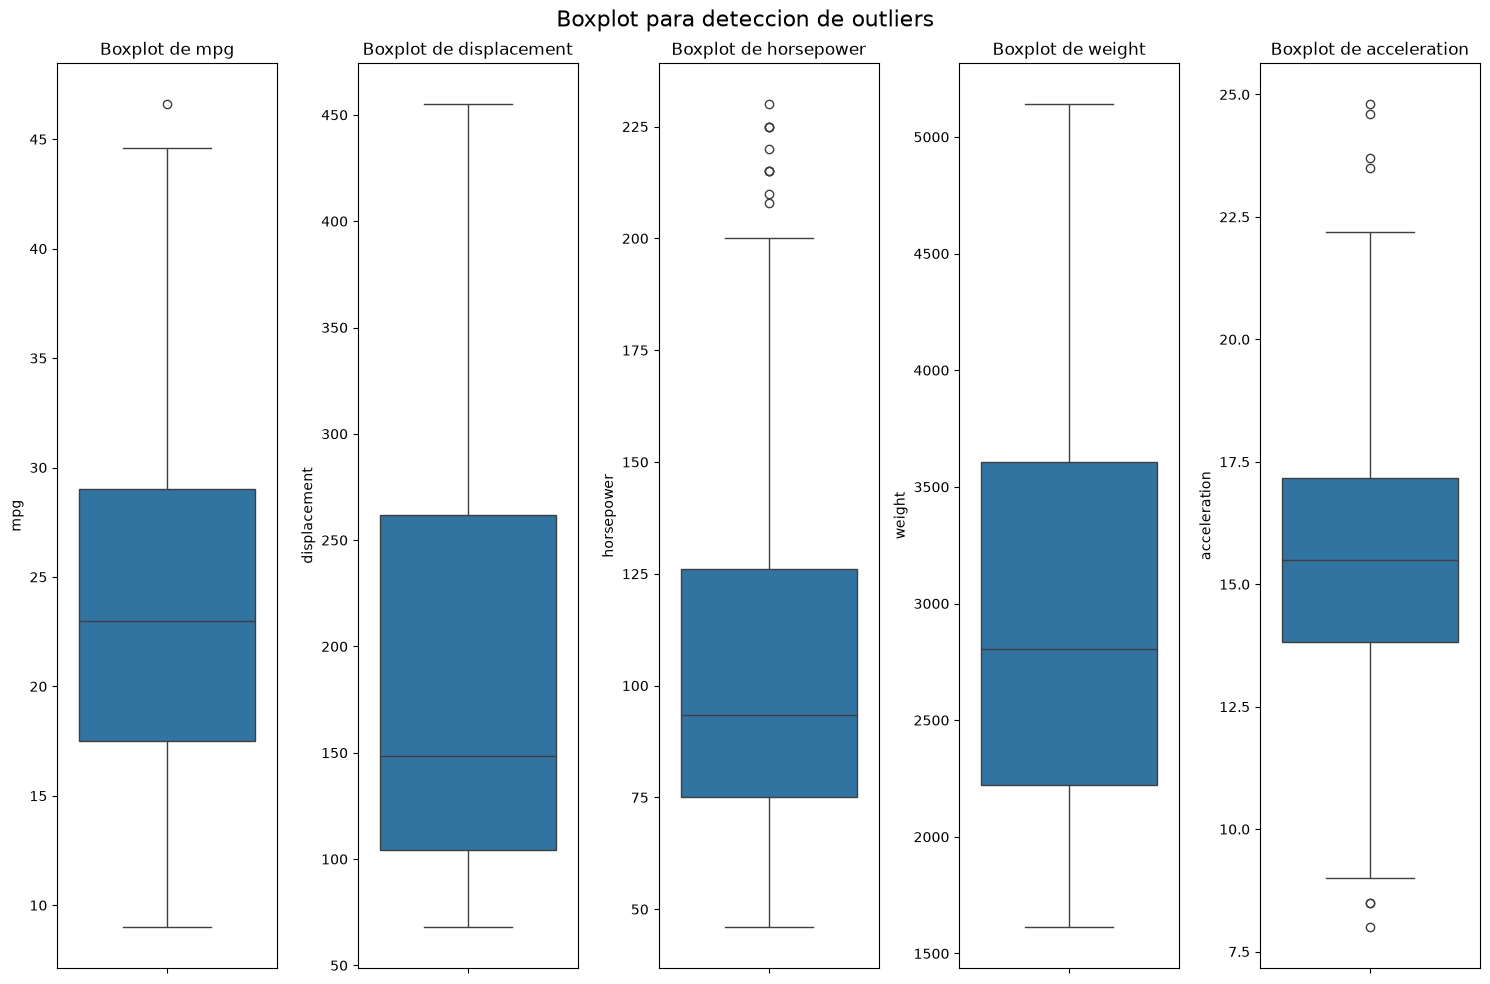

In [82]:
#Outliers
#mpg: Tiene un solo valor extremo, 46.6 mpg, que es un vehiculo muy eficiente.
#displacement y weight: Sin outliers,
#horsepower: Varios valores por encima de 200 hp, que son los vehiculos de 8 cilindros, comunes en los años 70 y 80.
#acceleration: Tiene extremos en ambos lados, los vehiculos mas rapidos y los mas lentos.
#No parece que los outliers sean errores de medicion, sino vehiculos extremos.
fig, axes = plt.subplots(1, len(num_cols), figsize=(15, 10))
for ax, col in zip(axes, num_cols):
    sns.boxplot(y=df_eda[col],ax=ax)
    ax.set_title(f'Boxplot de {col}')
plt.suptitle('Boxplot para deteccion de outliers', fontsize=16)
plt.tight_layout()
plt.show()


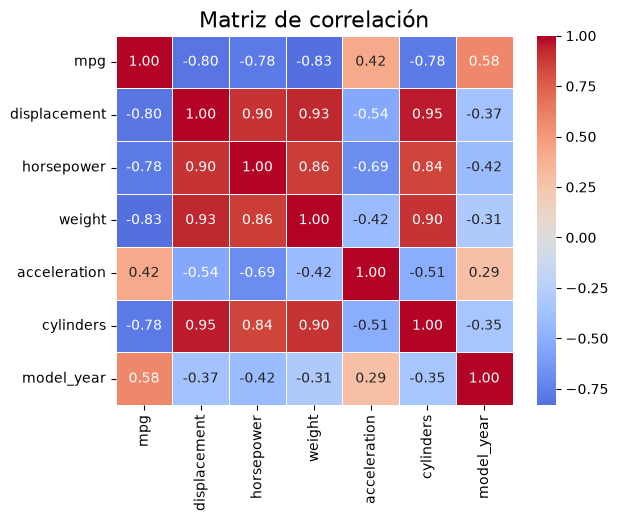

In [83]:

# Matriz de correlacion
# Negativas y fuertes: mpg con displacement, horsepower , weight y cylinder. Cuanto mas grande el motor, mas pesado y mas cilindros, menos eficiente es el vehiculo.
# Positiva moderada. mpg con model_year, los autos mas nuevos son mas eficientes.
# Posiva debil. mpg con acceleration, los autos lentos son los de poca potencia (horsepower) y esos consumen menos.
# Multicolinealidad: displacement, horsepower, weight y cylinders están muy correlacionadas entre sí 
corr = df_eda[num_cols + ['cylinders', 'model_year']].corr()
plt.Figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5, center = 0)
plt.title('Matriz de correlación', fontsize=16)
plt.show()


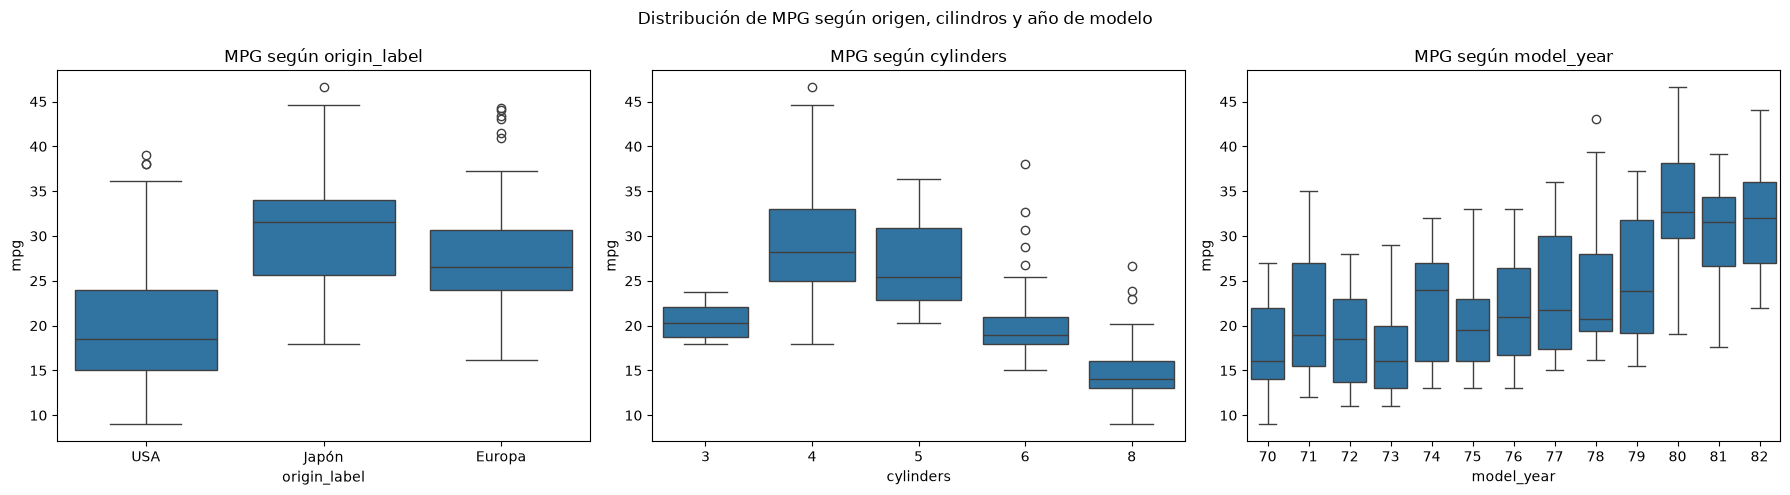

In [84]:

#MPG Segun origen, cilindros y año de modelo
# origin: Japon tiene la mediana mas alta, seguido de Europa y USA. Esta diferencia se explica porque USA fabrica la mayoria de los autos de 6 y 8 cilindros.
# cylinders: :os de 4 cilindros son los más eficientes y el consumo empeora con 6 y 8. Los de 3 y 5 cilindros se salen del patron, pero son tan pocos que no permiten conclusiones.
# model_year: tendencia creciente clara de eficiencia, los autos mas nuevos son mas eficientes. 
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, col in zip(axes, ['origin_label', 'cylinders', 'model_year']):
    sns.boxplot(data=df_eda, x=col, y='mpg', ax=ax)
    ax.set_title(f'MPG según {col}')
plt.suptitle('Distribución de MPG según origen, cilindros y año de modelo')
plt.tight_layout()
plt.show()

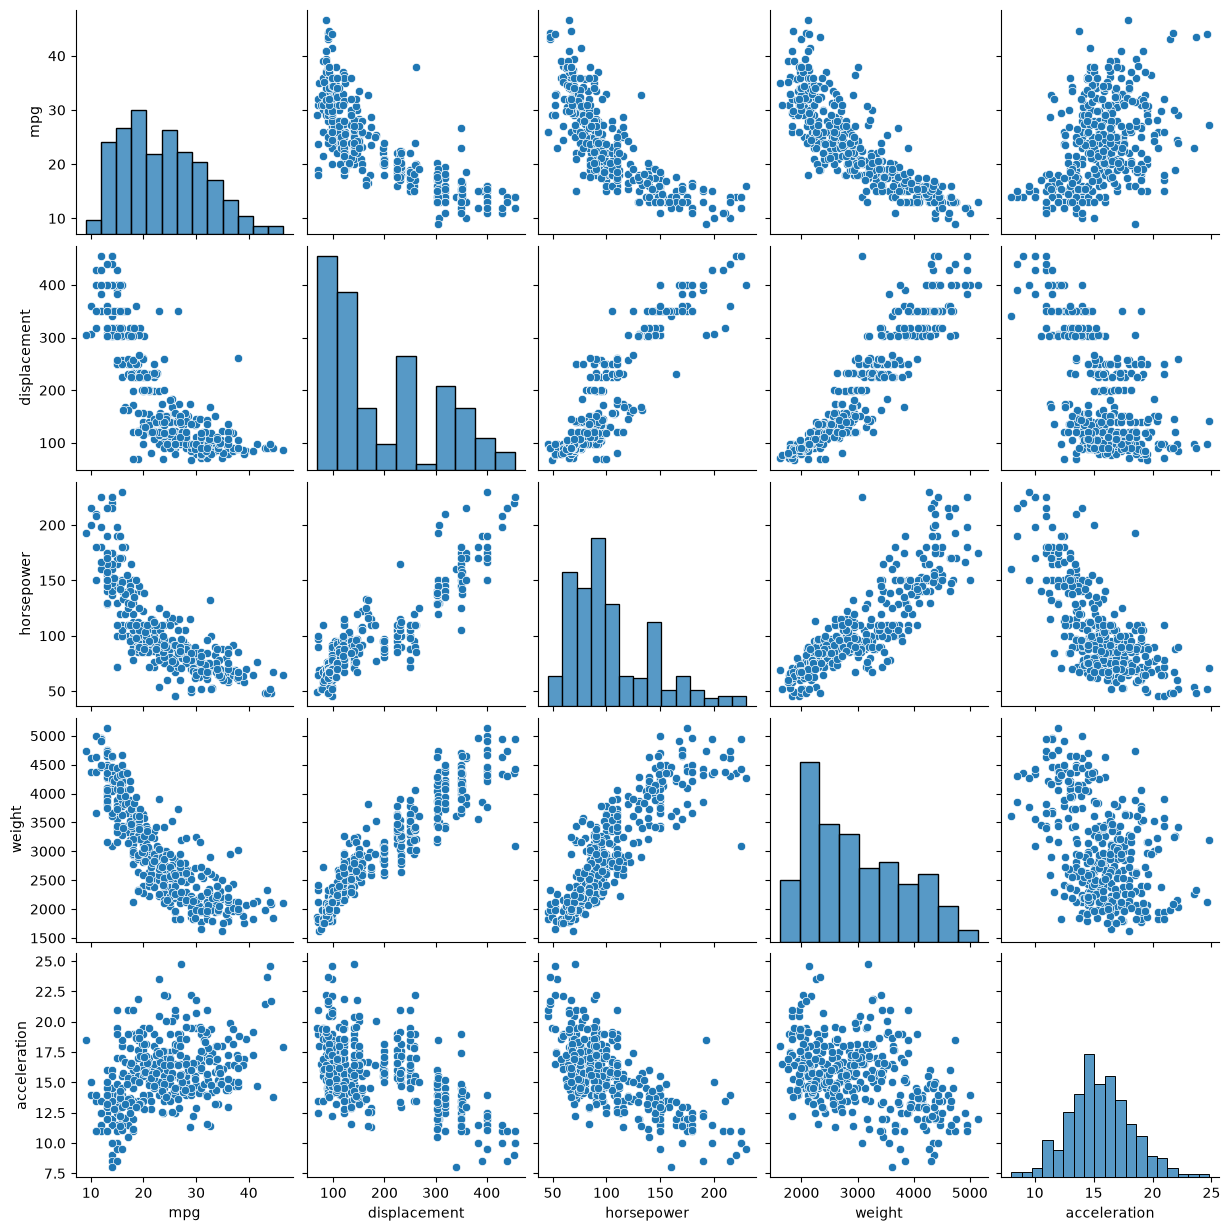

In [85]:
#Relaciones entre variables numericas
# mpg frente a weight, displacement y horsepower: relaciones decrecientes, muy similares y curvas, no son lineales.
# mpg cae rapido en autos ligeros y se aplana en los pesados.
# displacement, horsepower y weight forman relaciones lineales entre si, confirman multicolinealidad.
sns.pairplot(df_eda[num_cols])
plt.show()

# 3. Limpieza de datos

In [86]:
#Copia de trabajo para la limpieza de datos.
df_clean = df.copy()

#No hay duplicados exactos ni duplicados en features y target ignorando car_name
print("Duplicados exactos", df_clean.duplicated().sum())
cols_sin_id = df_clean.columns.drop('car_name')
print("Duplicados sin car_name:", df_clean.duplicated(subset=cols_sin_id).sum())

# Los car_name repetidos corresponden al mismo modelo en distintos años o versiones (legitimos).
# Caso dudoso: ['vw,rabbit' y 'volkswagen,rabbit']  del 76 nombres casi iguales, ademas  valores casi iguales pero no identicos. No se puede confirmar que sean el mismo registro: se mantienen ambos.
repetidos = df_clean[df_clean['car_name'].duplicated(keep=False)].sort_values('car_name')
display(repetidos)

Duplicados exactos 0
Duplicados sin car_name: 0


,car_name,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,mpg
257,"amc,concord",6,232.0,90.0,3210,17.2,78,1,19.4
315,"amc,concord",4,151.0,90.0,3003,20.1,80,1,24.3
24,"amc,gremlin",6,199.0,90.0,2648,15.0,70,1,21.0
33,"amc,gremlin",6,232.0,100.0,2634,13.0,71,1,19.0
107,"amc,gremlin",6,232.0,100.0,2789,15.0,73,1,18.0
...,...,...,...,...,...,...,...,...,...
240,"volkswagen,dasher",4,97.0,78.0,2190,14.1,77,2,30.5
175,"volkswagen,rabbit",4,90.0,70.0,1937,14.0,75,2,29.0
203,"volkswagen,rabbit",4,97.0,71.0,1825,12.2,76,2,29.5
197,"vw,rabbit",4,90.0,70.0,1937,14.2,76,2,29.0


In [87]:
# Note hay inconsistencias con los nombres de los autos, pero como car_name no es feature, no afecta el modelo.
correcciones = {
    'maxda': 'mazda',
    'chevroelt': 'chevrolet',
    'chevy': 'chevrolet',
    'vokswagen': 'volkswagen',

    'vw': 'volkswagen',
    'toyouta': 'toyota',
    'mercedes': 'mercedes-benz',
}

s = df_clean['car_name'].str.strip().str.lower()
for mal, bien in correcciones.items():
    s = s.str.replace(rf'^{mal}(?=[\s,]|$)', bien, regex=True)
df_clean['car_name'] = s

# verificación despues de corregir
display(df_clean['car_name'].str.split(',').str[0].value_counts().sort_index())


car_name
amc              28
audi              7
bmw               2
buick            17
cadillac          2
capri             1
chevrolet        47
chrysler          6
datsun           23
dodge            28
fiat              8
ford             51
hi                1
honda            13
mazda            12
mercedes-benz     3
mercury          11
nissan            1
oldsmobile       10
opel              4
peugeot           8
plymouth         31
pontiac          16
renault           5
saab              4
subaru            4
toyota           26
triumph           1
volkswagen       22
volvo             6
Name: count, dtype: int64

In [88]:
# 6 registros sin horsepower: 5 carros de 4 cilindros y 1 de 6
# Se va a imputar horsepower con displacement, la variable mas correlacionada. Como displacement es continua, se ajusta una regresion lineal simple.Tiene relacion casi lineal en el pairplot y se predicen los 6 valores faltantes.
# Para evitar data leakage, la regresion se ajusta solo con el train, después del split.
display(df_clean[df_clean['horsepower'].isna()])

,car_name,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,mpg
32,"ford,pinto",4,98.0,NaN,2046,19.0,71,1,25.0
126,"ford,maverick",6,200.0,NaN,2875,17.0,74,1,21.0
330,"renault,lecar,deluxe",4,85.0,NaN,1835,17.3,80,2,40.9
336,"ford,mustang,cobra",4,140.0,NaN,2905,14.3,80,1,23.6
354,"renault,18i",4,100.0,NaN,2320,15.8,81,2,34.5
374,"amc,concord,dl",4,151.0,NaN,3035,20.5,82,1,23.0


In [89]:
# Criterio IQR (el mismo de los boxplots): mpg 1, horsepower 10, acceleration 7; displacement y weight 0
for col in ['mpg', 'displacement', 'horsepower', 'weight', 'acceleration']:
    q1, q3 = df_clean[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    mask = (df_clean[col] < q1 - 1.5 * iqr) | (df_clean[col] > q3 + 1.5 * iqr)
    print(f"{col}: {mask.sum()} outliers")

# Los 10 outliers de horsepower son V8 estadounidenses de tamaño grande (Impala, Catalina, Fury, Electra), con un consumo bajo (10–16 mpg) coherente con su potencia.
# Se mantienen todos los outliers. Son vehículos reales en los extremos de su gama, no errores de captura; eliminarlos impediría al modelo predecir esos vehiculos.
q1, q3 = df_clean['horsepower'].quantile([0.25, 0.75])
display(df_clean[df_clean['horsepower'] > q3 + 1.5 * (q3 - q1)][['car_name', 'cylinders', 'horsepower', 'acceleration', 'mpg']])

mpg: 1 outliers
displacement: 0 outliers
horsepower: 10 outliers
weight: 0 outliers
acceleration: 7 outliers


,car_name,cylinders,horsepower,acceleration,mpg
6,"chevrolet,impala",8,220.0,9.0,14.0
7,"plymouth,fury,iii",8,215.0,8.5,14.0
8,"pontiac,catalina",8,225.0,10.0,14.0
13,"buick,estate,wagon,(sw)",8,225.0,10.0,14.0
25,"ford,f250",8,215.0,14.0,10.0
27,"dodge,d200",8,210.0,13.5,11.0
67,"mercury,marquis",8,208.0,11.0,11.0
94,"chrysler,new,yorker,brougham",8,215.0,11.0,13.0
95,"buick,electra,225,custom",8,225.0,11.0,12.0
116,"pontiac,grand,prix",8,230.0,9.5,16.0


In [90]:
# origin: categórica nominal guardada como entero => one-hot encoding.
# No aprende nada de los datos (las 3 categorías son fijas), asi que no genera leakage
#  drop_first=True: se elimina origin_Europa, que queda como categoría de referencia.
df_clean['origin'] = df_clean['origin'].map({1: 'USA', 2: 'Europa', 3: 'Japón'})
df_clean = pd.get_dummies(df_clean, columns=['origin'], prefix='origin', drop_first=True, dtype=int)

df_clean.head()

,car_name,cylinders,displacement,horsepower,weight,acceleration,model_year,mpg,origin_Japón,origin_USA
0,"chevrolet,chevelle,malibu",8,307.0,130.0,3504,12.0,70,18.0,0,1
1,"buick,skylark,320",8,350.0,165.0,3693,11.5,70,15.0,0,1
2,"plymouth,satellite",8,318.0,150.0,3436,11.0,70,18.0,0,1
3,"amc,rebel,sst",8,304.0,150.0,3433,12.0,70,16.0,0,1
4,"ford,torino",8,302.0,140.0,3449,10.5,70,17.0,0,1


In [91]:
#Revision del dataset clean
print("Registros y columnas:", df_clean.shape)
df_clean.info()

Registros y columnas: (398, 10)
<class 'pandas.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   car_name      398 non-null    str    
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   mpg           398 non-null    float64
 8   origin_Japón  398 non-null    int64  
 9   origin_USA    398 non-null    int64  
dtypes: float64(4), int64(5), str(1)
memory usage: 37.5 KB


# 4. Modelo base

In [92]:
# Parametros del experimento
params = {
    'test_size': 0.2,
    'random_state': RANDOM_STATE,
    'modelo': 'LinearRegression',
    'imputacion_horsepower': 'regresion_lineal_sobre_displacement',
    'estratificacion': 'quintiles_de_mpg',
}

In [93]:
# Se excluyen car_name (ID, alta cardinalidad) y mpg (target). Quedan 8 features.
X = df_clean.drop(columns=['car_name', 'mpg'])
y = df_clean['mpg']

In [94]:
# Split 80-20 estratificado por quantiles de mpg, para que train y test tengan una distribucion similar del target
#318 Registros en train y 80 en test. Las medias de mpg son casi iguales (23.56 frente a 23.34), lo que confirma que la estratificacion funciono. Los 6 faltantes de horsepower quedaron 4 en train y 2 en test.
mpg_bins = pd.qcut(y, q=5, labels=False)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=params['test_size'],
    random_state=params['random_state'],
    stratify=mpg_bins
)

print("Train:", X_train.shape, " Test:", X_test.shape)
print("Faltantes en train:", X_train['horsepower'].isna().sum(), " en test:", X_test['horsepower'].isna().sum())

# Comprobacion de la estratificacion: medias de mpg similares en train y test
print(f"mpg media train: {y_train.mean():.2f}  test: {y_test.mean():.2f}")

Train: (318, 8)  Test: (80, 8)
Faltantes en train: 4  en test: 2
mpg media train: 23.56  test: 23.34


In [95]:
# Imputacion de horsepower: regresion lineal simple sobre displacement, ajustada solo con el train (evita leakage)
# Las predicciones se redondean porque horsepower solo contiene valores enteros.
X_train = X_train.copy()
X_test = X_test.copy()

con_hp = X_train['horsepower'].notna()
imputador_hp = LinearRegression()
imputador_hp.fit(X_train.loc[con_hp, ['displacement']], X_train.loc[con_hp, 'horsepower'])

for X_set in (X_train, X_test):
    faltan = X_set['horsepower'].isna()
    if faltan.any():
        X_set.loc[faltan, 'horsepower'] = imputador_hp.predict(X_set.loc[faltan, ['displacement']]).round()
#Como resultado  0 faltantes en train y en test.
print("Faltantes tras imputar → train:", X_train['horsepower'].isna().sum(), " test:", X_test['horsepower'].isna().sum())

Faltantes tras imputar → train: 0  test: 0


In [96]:
# Referencia base: predice siempre la media de mpg del train
dummy = DummyRegressor(strategy='mean')
dummy.fit(X_train, y_train)

# Modelo base: regresión lineal múltiple
modelo = LinearRegression()
modelo.fit(X_train, y_train)

# Prediccion del modelo para el primer auto del dataset, para verificar el calculo manual.
#Solo es un ejemplo: el modelo predice 14.79 y el valor real es de 18, se equivoca por 3.21 mpg aproximadamente. 
display(X.iloc[[0]])
print("Prediccion del modelo:", modelo.predict(X.iloc[[0]]).round(2))
print("Valor real:", y.iloc[0])

,cylinders,displacement,horsepower,weight,acceleration,model_year,origin_Japón,origin_USA
0,8,307.0,130.0,3504,12.0,70,0,1


Prediccion del modelo: [14.79]
Valor real: 18.0


# 5. Evaluar el modelo

In [97]:
def evaluar(nombre, modelo, X, y):
    pred = modelo.predict(X)
    return {
        'modelo': nombre,
        'RMSE': np.sqrt(mean_squared_error(y, pred)),
        'MAE': mean_absolute_error(y, pred),
        'R2': r2_score(y, pred),
    }

resultados = pd.DataFrame([
    {**evaluar('Dummy (media)', dummy, X_train, y_train), 'conjunto': 'train'},
    {**evaluar('Dummy (media)', dummy, X_test, y_test), 'conjunto': 'test'},
    {**evaluar('LinearRegression', modelo, X_train, y_train), 'conjunto': 'train'},
    {**evaluar('LinearRegression', modelo, X_test, y_test), 'conjunto': 'test'},
]).round(3)
display(resultados)

#Metricas del modelo en test
#El modelo se equivoca en promedio 2.5 frende a 6.5 si siempre adivinaramos la media.
#Train y test dan casi los mismos valores: asumo que no memorizo. Aunque el error no es bajo.
metricas = evaluar('LinearRegression', modelo, X_test, y_test)
metricas.pop('modelo')

,modelo,RMSE,MAE,R2,conjunto
0,Dummy (media),7.829,6.568,0.000,train
1,Dummy (media),7.714,6.408,-0.001,test
2,LinearRegression,3.282,2.506,0.824,train
3,LinearRegression,3.232,2.553,0.824,test


'LinearRegression'

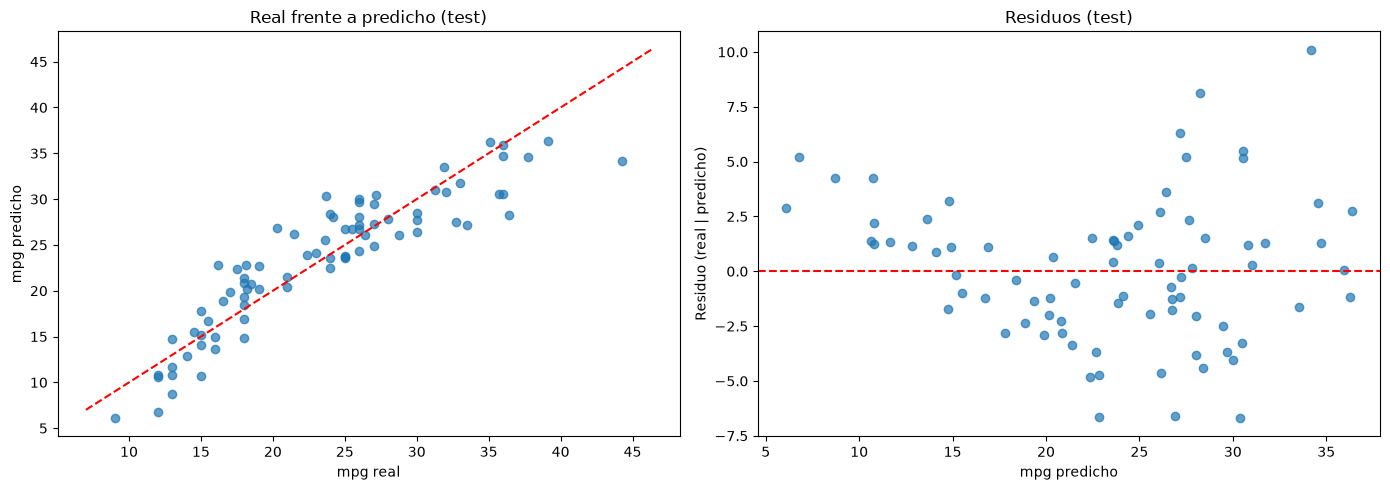

In [99]:
pred_test = modelo.predict(X_test)
residuos = y_test - pred_test

fig_residuos, axes = plt.subplots(1, 2, figsize=(14, 5))

# Real frente a predicho: un modelo perfecto pondria todos los puntos sobre la diagonal
axes[0].scatter(y_test, pred_test, alpha=0.7)
lims = [y_test.min() - 2, y_test.max() + 2]
axes[0].plot(lims, lims, 'r--')
axes[0].set_xlabel('mpg real')
axes[0].set_ylabel('mpg predicho')
axes[0].set_title('Real frente a predicho (test)')

# Residuos: deberian estar repartidos al azar alrededor de 0
#El modelo se queda corto con los autos que gastan mucho y con los muy eficientesy se pasa con los intermedios.
#Se anticipaba desde el EDA que el consumo cambia la curva y el modelo solo sabe trazar rectas. Tengo dos opciones: transformar mpg o usar un modelo que capte curvas.
axes[1].scatter(pred_test, residuos, alpha=0.7)
axes[1].axhline(0, color='r', linestyle='--')
axes[1].set_xlabel('mpg predicho')
axes[1].set_ylabel('Residuo (real | predicho)')
axes[1].set_title('Residuos (test)')

plt.tight_layout()
plt.show()

# 6. Registrar el experimento en MLFlow

In [ ]:
mlflow.set_tracking_uri("sqlite:///mlflow.db")
mlflow.set_experiment("auto-mpg")

In [100]:
with mlflow.start_run(run_name="baseline_regresion_lineal"):

    # Parametros: las decisiones que tomamos previamente
    mlflow.log_params(params)
    mlflow.log_param("n_train", len(X_train))
    mlflow.log_param("n_test", len(X_test))
    mlflow.log_param("features", list(X_train.columns))

    # Metricas del modelo en test
    mlflow.log_metrics(metricas)

    # Metricas del dummy, para comparar en la misma pantalla
    metricas_dummy = evaluar('Dummy', dummy, X_test, y_test)
    metricas_dummy.pop('modelo')
    mlflow.log_metrics({f"dummy_{k}": v for k, v in metricas_dummy.items()})

    # Etiquetas para encontrar el run facilmente
    mlflow.set_tag("etapa", "baseline")
    mlflow.set_tag("dataset", "UCI Auto MPG (id 9)")

    # Artefactos: el grafico de residuos y el modelo entrenado
    mlflow.log_figure(fig_residuos, "residuos_test.png")
    mlflow.sklearn.log_model(modelo, name="modelo", input_example=X_train.head(3))

print("Run registrado")

2026/10/04 12:26:12 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/04 12:26:12 INFO mlflow.store.db.utils: Updating database tables
c:\Users\FernandoSoft\.conda\envs\mlops\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(

Run registrado


mlflow ui --backend-store-uri sqlite:///mlflow.db

7. Reflexion 

**Mejoras al flujo.** Primero, empaquetaría la imputación de 'horsepower' y la codificación de 'origin' en un 'Pipeline' junto con el modelo: hoy se hacen fuera de él, y si alguien carga el modelo y le pasa un auto sin potencia o con 'origin = 2', la predicción será errónea. Segundo, completaría la reproducibilidad: MLflow registró parámetros, métricas y artefactos, pero no la versión de los datos, del código ni de las librerías. Tercero, convertiría el notebook en scripts para reentrenar automáticamente, comparar cada modelo contra el anterior en MLflow y monitorearlo en producción.

**En mi área profesional** (seguridad informática) aplicaría estos aprendizajes a un modelo de análisis del comportamiento de usuarios: a partir de sus hábitos de actividad de red, estimaría la probabilidad de que un empleado se vea involucrado en un incidente, y según su nivel de riesgo aplicaría capacitación o controles compensatorios antes de que ocurra. Sería un problema supervisado, porque los incidentes se registran formalmente, aunque la falta de análisis forense afectaría la calidad de las etiquetas. Además, los incidentes son pocos frente al total de empleados: la accuracy sería engañosa y habría que usar precision y recall, y definir los umbrales de riesgo según el costo de cada tipo de error. Por último, los patrones de ataque cambian constantemente, así que sin monitoreo el modelo se degradaría en silencio, la deuda técnica que vimos en las lecturas. El monitoreo y el reentrenamiento serían indispensables.

Durante la elaboración de este trabajo se utilizó Claude (Anthropic, versión Opus 5.5) como herramienta de apoyo para organizar ideas en la etapa de reflexión y para resolver dudas puntuales de sintaxis de programación. La herramienta no se empleó para generar el texto ni el código entregado; todo el contenido fue redactado, implementado y revisado por el autor, quien asume plena responsabilidad sobre él.
Anthropic. (2026). Claude (versión Opus 5.5) [Modelo de lenguaje de gran tamaño]. https://claude.ai